In [ ]:
import gdown
import zipfile
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os, sys
if not os.path.exists('ImageClassification'):
    !git clone https://github.com/durak-dev/ImageClassification.git
sys.path.append('ImageClassification')

from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Model, Sequential
# CNN and classifier layers
from tensorflow.keras.layers import (
    Conv2D,       # Apply convolution filters to an image
    MaxPooling2D, # Reduce the spatial dimensions of feature maps
    Flatten,      # Convert feature maps into a one-dimensional vector
    Dense,        # Connect units to classify the image
    Dropout       # Randomly deactivate units during training
)

# EarlyStopping: stop training when validation performance stops improving
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
# 1. Download the file from Google Drive
url = 'https://drive.google.com/file/d/1nD6OujVURzL-nEKvsf_KO-nhsQlQSbuw/view?usp=sharing'
file_id = url.split('/')[-2]
download_url = f'https://drive.google.com/uc?id={file_id}'
archive_filename = 'dataset.zip'

print("Downloading dataset...")
gdown.download(download_url, archive_filename, quiet=True)

# 2. Extract the ZIP file
extract_folder = 'dataset_extracted'
print("Extracting files...")
with zipfile.ZipFile(archive_filename, 'r') as zip_ref:
    zip_ref.extractall(extract_folder)

# 3. List extracted contents
print("Extracted contents:", os.listdir(extract_folder))

# 4. Read the labels/metadata CSV inside the folder
labels_path = os.path.join(extract_folder, 'labels.csv')
if os.path.exists(labels_path):
    df = pd.read_csv(labels_path)
    print("\nSuccess! 'labels.csv' loaded into DataFrame 'df':")
    display(df.head())
else:
    print(f"\nCould not find 'labels.csv' in {extract_folder}")

Extracting files...
Extracted contents: ['labels.csv', 'README.txt', 'images']

Success! 'labels.csv' loaded into DataFrame 'df':


,filename,class_id,description
0,image_000001.JPEG,n03042490,cliff dwelling
1,image_000002.JPEG,n02793495,barn
2,image_000003.JPEG,n02793495,barn
3,image_000004.JPEG,n02793495,barn
4,image_000005.JPEG,n02793495,barn


In [3]:
df['path'] = extract_folder + '/images/' + df.filename
missing = ~df.path.map(os.path.exists)
print(missing.sum(), "missing files")

0 missing files


In [4]:
df['class_id'] = df['class_id'].map(lambda x: int(x[1:]) if str(x).startswith('n') else x)

In [5]:
unique_pairs = df[['class_id', 'description']].drop_duplicates()

conflicts_by_id = unique_pairs[unique_pairs.duplicated(subset=['class_id'], keep=False)].sort_values('class_id')

conflicts_by_desc = unique_pairs[unique_pairs.duplicated(subset=['description'], keep=False)].sort_values('description')

print("Conflicting ID mappings:")
print(conflicts_by_id)

Conflicting ID mappings:
Empty DataFrame
Columns: [class_id, description]
Index: []


In [ ]:
from ImageClassification.utils.funcs import plot_images

ModuleNotFoundError: No module named 'ImageClassification.utils'

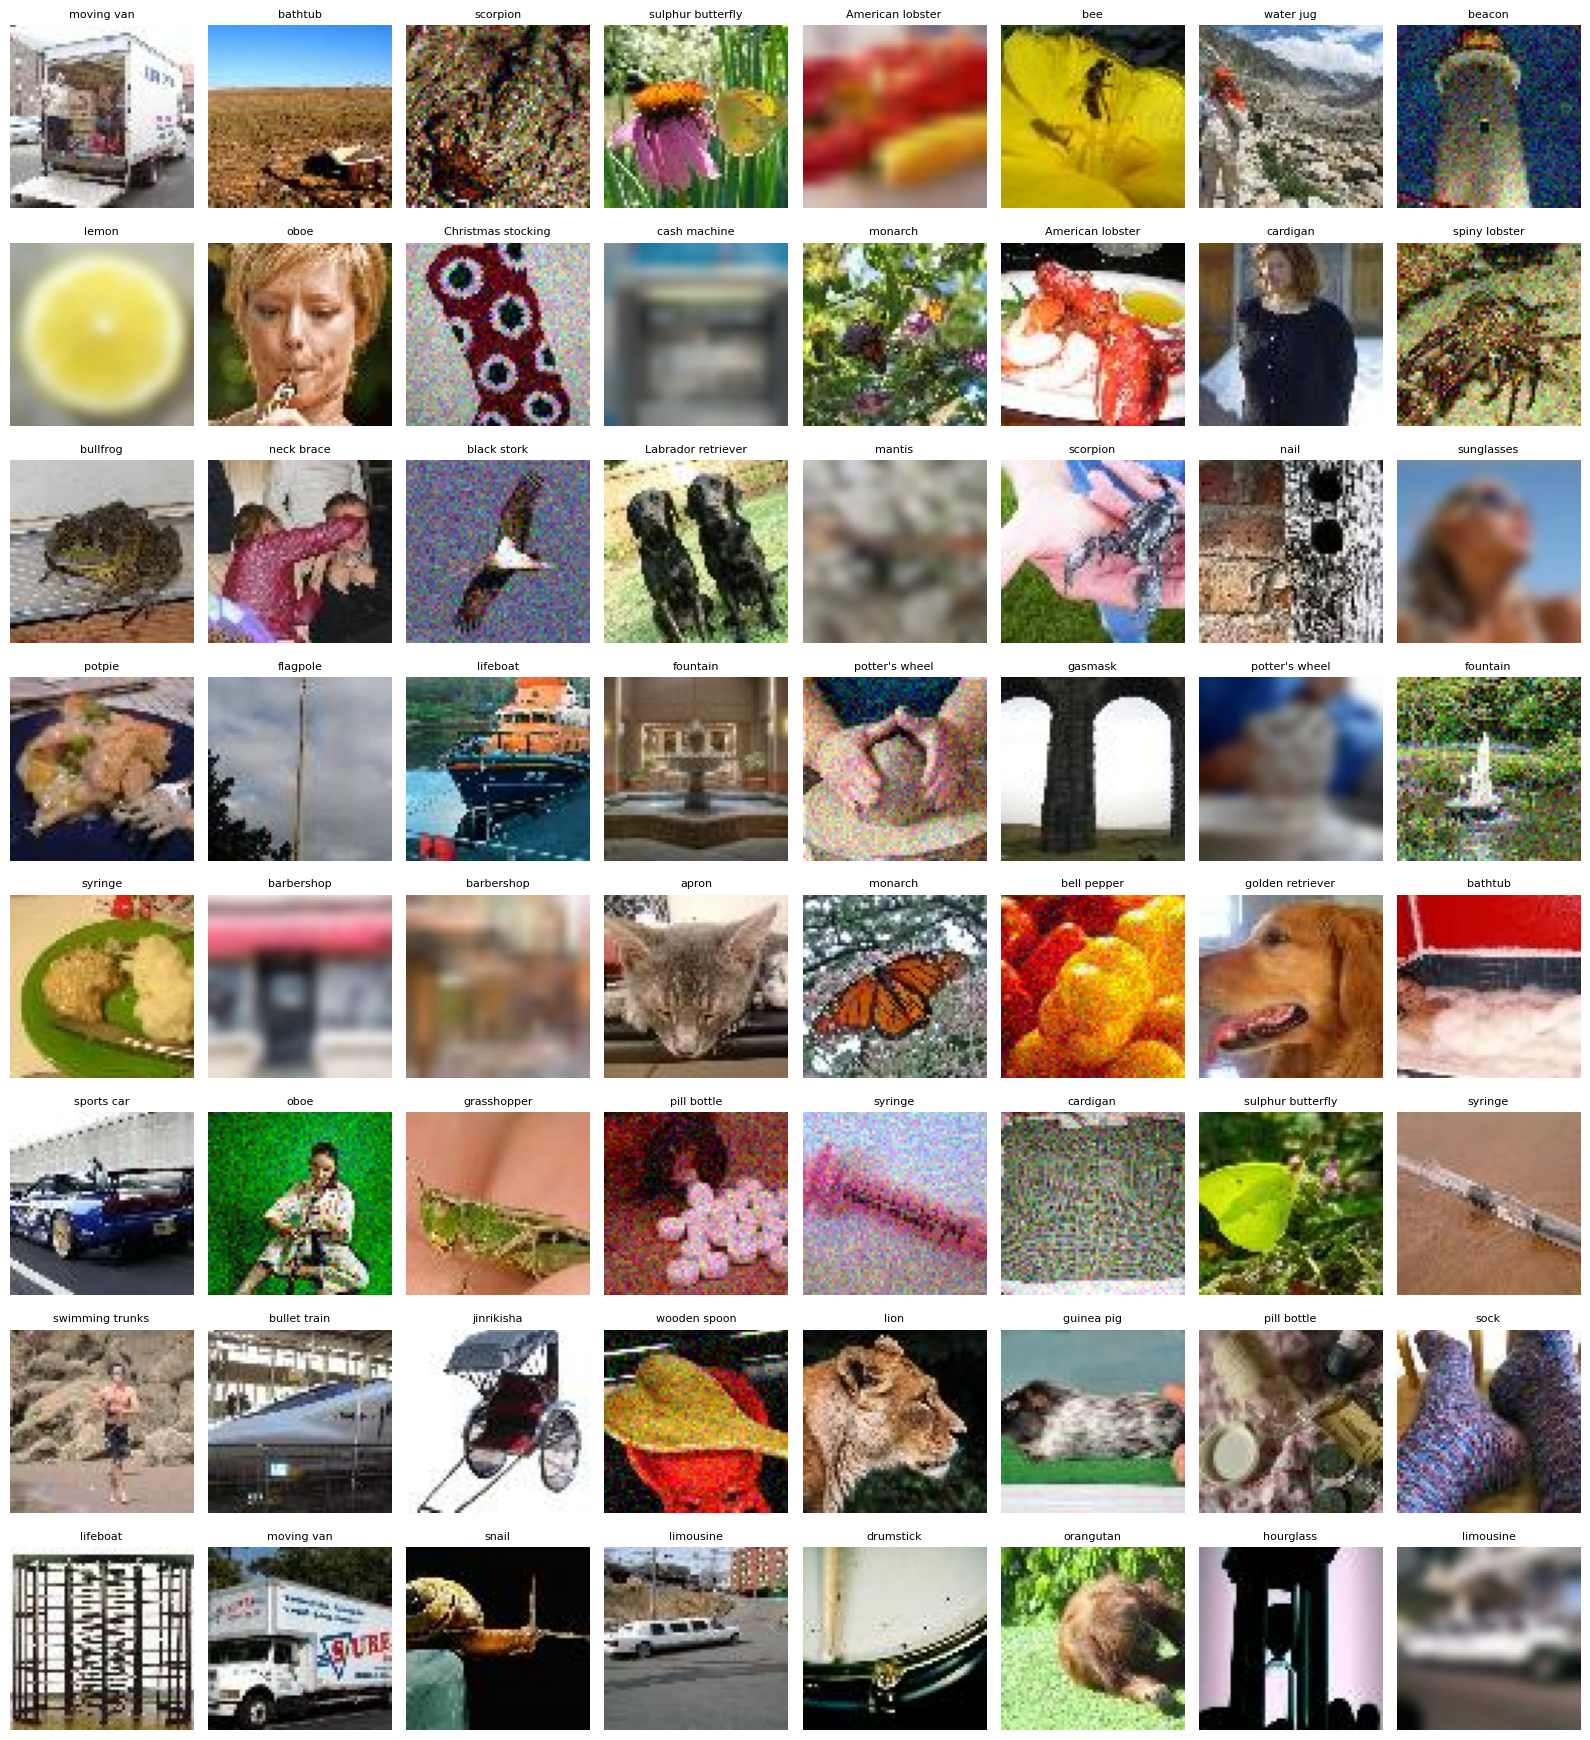

In [45]:

rng = np.random.default_rng(420)  # change or remove the seed for different samples
pairs = unique_pairs.values
idx = rng.choice(len(pairs), size=64, replace=False)

plot_images(df, n=64, shuffle=True, title_cols='description')

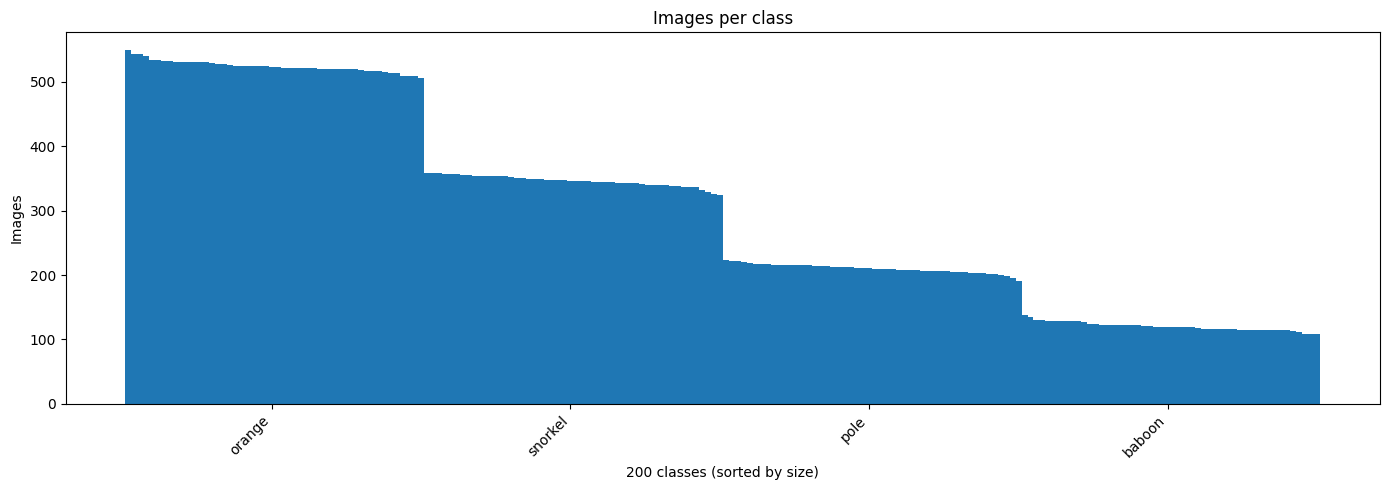

In [26]:
counts = df.groupby('class_id').size().sort_values(ascending=False)
plt.figure(figsize=(14, 5))
plt.bar(range(len(counts)), counts.values, width=1.0)
desc = df.drop_duplicates('class_id').set_index('class_id').description
pos = [24, 74, 124, 174]
plt.xticks(pos, [desc[counts.index[i]].split(',')[0] for i in pos], rotation=45, ha='right')
plt.xlabel(f'{len(counts)} classes (sorted by size)')
plt.ylabel('Images'); plt.title('Images per class')
plt.tight_layout(); plt.show()

In [36]:
import torch
from transformers import CLIPModel, CLIPProcessor
from sklearn.metrics import confusion_matrix

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
model = CLIPModel.from_pretrained('openai/clip-vit-base-patch32').to(dev).eval()
proc = CLIPProcessor.from_pretrained('openai/clip-vit-base-patch32')

def feats(out):
    f = out if torch.is_tensor(out) else out.pooler_output
    return f / f.norm(dim=-1, keepdim=True)

classes = df.drop_duplicates('class_id')[['class_id', 'description']].reset_index(drop=True)
prompts = [f"a photo of a {d.split(',')[0]}" for d in classes.description]
with torch.no_grad():
    t = proc(text=prompts, return_tensors='pt', padding=True).to(dev)
    txt = feats(model.get_text_features(**t))

samp = df.groupby('class_id', group_keys=False).apply(lambda g: g.sample(min(20, len(g)), random_state=0))
cid2i = {c: i for i, c in enumerate(classes.class_id)}
y_true = samp.class_id.map(cid2i).values

sims = []
for i in range(0, len(paths), 64):
    ims = [Image.open(p).convert('RGB') for p in paths[i:i+64]]
    with torch.no_grad():
        x = proc(images=ims, return_tensors='pt').to(dev)
        f = feats(model.get_image_features(**x))
    sims.append((f @ txt.T).cpu())
sims = torch.cat(sims)                                         # (N, n) cosine similarities
y_pred = sims.argmax(1).numpy()
clip_score = (model.logit_scale.exp().item() * sims).softmax(1).max(1).values.numpy()
print("top 1:", np.mean(y_true == y_pred),
      "top 5:", (sims.topk(5).indices.numpy() == y_true[:, None]).any(1).mean())

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

top 1: 0.42875 top 5: 0.631


In [37]:
T = txt.float().cpu().numpy()
T = T - T.mean(0)                                  # remove the shared "a photo of a" component
T /= np.linalg.norm(T, axis=1, keepdims=True)
S = T @ T.T
np.fill_diagonal(S, -np.inf)
nbr_rank = (-S).argsort(1).argsort(1) + 1          # nbr_rank[i, j] == 1: j is the class closest in meaning to i
K = 5

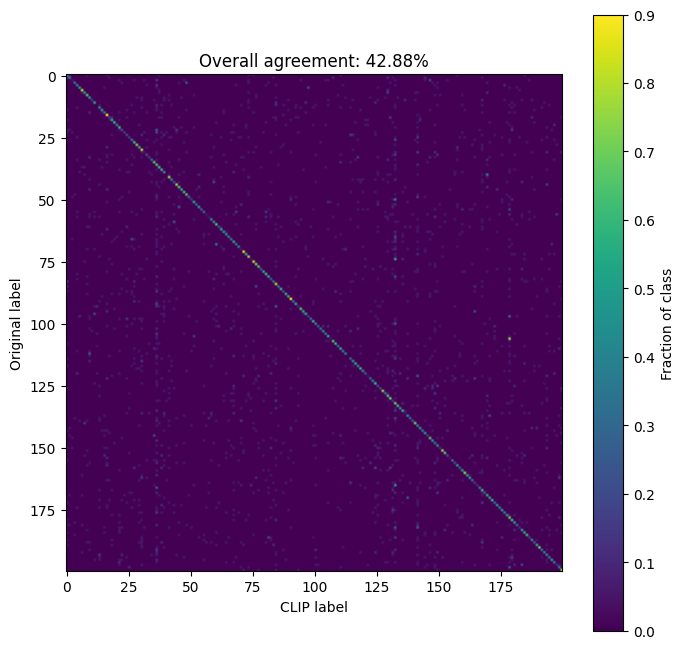

In [41]:
n = len(classes)
cm = confusion_matrix(y_true, y_pred, labels=range(n))
cmn = cm / cm.sum(1, keepdims=True)

plt.figure(figsize=(8, 8))
plt.imshow(cmn, cmap='viridis'); plt.colorbar(label='Fraction of class')
plt.xlabel('CLIP label'); plt.ylabel('Original label')
plt.title(f'Overall agreement: {np.mean(y_true == y_pred):.2%}')
plt.show()

# Per-class: where does each folder mostly go?
top = cmn.argmax(1)
summary = pd.DataFrame({
    'original': classes.description.str.split(',').str[0],
    'clip_top': classes.description.str.split(',').str[0].values[top],
    'frac_top': cmn.max(1),
    'frac_self': np.diag(cmn),
})

In [1]:
top = cmn.argmax(1)
bad = summary[top != np.arange(n)].copy()          # indices, so two classes with the same first word can't collide
bad['nbr_rank'] = nbr_rank[bad.index, top[bad.index]]

suspect_cls = bad[bad.nbr_rank > K].sort_values('frac_top', ascending=False)
neighbor_cls = bad[bad.nbr_rank <= K].sort_values('frac_top', ascending=False)
print(f"{len(suspect_cls)} suspect classes, {len(neighbor_cls)} explained by semantic neighbours")
display(suspect_cls.head(40))

NameError: name 'cmn' is not defined

In [39]:
names = classes.description.str.split(',').str[0].values
res = pd.DataFrame({
    'path': samp.path.values,
    'original': names[y_true],
    'clip_pred': names[y_pred],
    'clip_score': clip_score,
    'nbr_rank': nbr_rank[y_true, y_pred],
})
res['kind'] = np.where(y_true == y_pred, 'agree',
               np.where(res.nbr_rank <= K, 'neighbor', 'suspect'))
print(res.kind.value_counts())

review = res[res.kind == 'suspect'].sort_values('clip_score', ascending=False)
display(review.head(30))      # most confident, semantically unrelated disagreements first

kind
suspect     1841
agree       1715
neighbor     444
Name: count, dtype: int64


,path,original,clip_pred,clip_score,nbr_rank,kind
1199,dataset_extracted/images/image_034759.JPEG,abacus,scoreboard,0.999920,8,suspect
3367,dataset_extracted/images/image_056364.JPEG,umbrella,sulphur butterfly,0.999787,140,suspect
1420,dataset_extracted/images/image_023056.JPEG,beacon,academic gown,0.999736,109,suspect
3768,dataset_extracted/images/image_048955.JPEG,banana,king penguin,0.999479,10,suspect
540,dataset_extracted/images/image_009235.JPEG,Labrador retriever,sulphur butterfly,0.998368,54,suspect
2559,dataset_extracted/images/image_036119.JPEG,parking meter,triumphal arch,0.998346,89,suspect
3297,dataset_extracted/images/image_009294.JPEG,tractor,sulphur butterfly,0.998266,133,suspect
3819,dataset_extracted/images/image_044296.JPEG,meat loaf,bell pepper,0.998258,42,suspect
3979,dataset_extracted/images/image_030270.JPEG,seashore,potpie,0.996483,127,suspect
3018,dataset_extracted/images/image_058201.JPEG,sombrero,dugong,0.995680,168,suspect


In [ ]:
plot_images(res, n=64 title_cols=['original', 'clip_pred']) 

: 